In [1]:
import nltk
for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(p, quiet=True)

i love reading books  i still remember reading my first book at my tuition which was given to me by teacher i had a very bad handwriting at that time so my teacher made me write a paragraph from that book in good handwriting  while writing paragraphs i developed interest in the plot of story in the novel  so i began reading the book after completing my task of writing the paragraph  

5 sentences
['i', 'love', 'reading', 'books', 'i', 'still', 'remember', 'reading', 'my', 'first', 'book', 'at', 'my', 'tuition', 'which', 'was', 'given', 'to', 'me', 'by', 'teacher', 'i', 'had', 'a', 'very', 'bad', 'handwriting', 'at', 'that', 'time', 'so', 'my', 'teacher', 'made', 'me', 'write', 'a', 'paragraph', 'from', 'that', 'book', 'in', 'good', 'handwriting', 'while', 'writing', 'paragraphs', 'i', 'developed', 'interest', 'in', 'the', 'plot', 'of', 'story', 'in', 'the', 'novel', 'so', 'i', 'began', 'reading', 'the', 'book', 'after', 'completing', 'my', 'task', 'of', 'writing', 'the', 'paragraph'] 


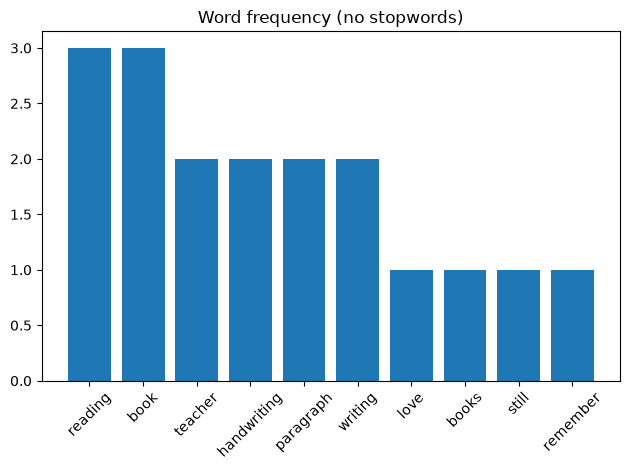

In [2]:
#Question1 
import re
from collections import Counter
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

text = ("I love reading books . "
        "I still remember reading my first book at my tuition which was given to me by teacher.. "
        "I had a very bad handwriting at that time so my teacher made me write a paragraph from that book in good handwriting . "
        "While writing paragraphs, I developed interest in the plot of story in the novel . "
        "So, I began reading the book after completing my task of writing the paragraph. "
        )

# 1. lowercase + remove punctuation
clean = re.sub(r'[^\w\s]', '', text.lower())
print(clean, "\n")

# 2. sentence and word tokens
sentences = sent_tokenize(text)
words = word_tokenize(clean)
print(len(sentences), "sentences")
print(words, "\n")

# 3. split() vs word_tokenize() on the raw text
print("split():       ", text.split()[:12])
print("word_tokenize():", word_tokenize(text)[:14])
# split keeps punctuation stuck to words (cousins, / wicket.), word_tokenize separates it into its own token

# 4. stopword removal
stop = set(stopwords.words('english'))
filtered = [w for w in words if w not in stop]
print("\n", filtered)

# 5. frequency distribution
freq = Counter(filtered)
print(freq.most_common(10))
top = freq.most_common(10)
plt.bar([w for w, _ in top], [c for _, c in top])
plt.xticks(rotation=45)
plt.title("Word frequency (no stopwords)")
plt.tight_layout()
plt.show()

In [3]:
#Q2
from nltk.stem import PorterStemmer, WordNetLemmatizer

# 1-2. alphabetic words only, then drop stopwords
alpha = re.findall(r'[a-zA-Z]+', text.lower())
tokens = [w for w in alpha if w not in stop]

# 3. stemming
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in tokens]

# 4. lemmatization
wl = WordNetLemmatizer()
lemmas = [wl.lemmatize(w) for w in tokens]

# 5. comparison
print(f"{'word':12}{'stem':12}{'lemma':12}")
for w, s, l in zip(tokens, stemmed, lemmas):
    print(f"{w:12}{s:12}{l:12}")

# stemming chops suffixes by rule, so it is fast but can give non-words (e.g. "loved" -> "love", "story" -> "stori").
# lemmatization uses a dictionary and returns real words, but is slower.
# I'd use stemming for search/indexing where speed matters and exact words don't,
# and lemmatization when the output has to stay readable or meaning matters (chatbots, sentiment, etc).

word        stem        lemma       
love        love        love        
reading     read        reading     
books       book        book        
still       still       still       
remember    rememb      remember    
reading     read        reading     
first       first       first       
book        book        book        
tuition     tuition     tuition     
given       given       given       
teacher     teacher     teacher     
bad         bad         bad         
handwriting handwrit    handwriting 
time        time        time        
teacher     teacher     teacher     
made        made        made        
write       write       write       
paragraph   paragraph   paragraph   
book        book        book        
good        good        good        
handwriting handwrit    handwriting 
writing     write       writing     
paragraphs  paragraph   paragraph   
developed   develop     developed   
interest    interest    interest    
plot        plot        plot        
s

In [4]:
#Q3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "The new phone has a great camera and the battery lasts all day",
    "Local team wins the cricket final after a thrilling last over",
    "Government announces new tax rules for small businesses this year",
]

# 1. Bag of words
cv = CountVectorizer()
bow = cv.fit_transform(texts)
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()), "\n")

# 2. TF-IDF
tv = TfidfVectorizer(stop_words='english')
tfidf = tv.fit_transform(texts)
names = tv.get_feature_names_out()

# 3. top 3 keywords per text
for i, row in enumerate(tfidf.toarray()):
    idx = row.argsort()[::-1][:3]
    print(f"Text {i+1}:", [(str(names[j]), round(float(row[j]), 3)) for j in idx])

# a high score means the word is frequent in that text but rare in the others, so it describes the text well
# the texts are very short so several words tie, but the top words are all specific to their own text

   after  all  and  announces  battery  businesses  camera  cricket  day  \
0      0    1    1          0        1           0       1        0    1   
1      1    0    0          0        0           0       0        1    0   
2      0    0    0          1        0           1       0        0    0   

   final  ...  phone  rules  small  tax  team  the  this  thrilling  wins  \
0      0  ...      1      0      0    0     0    2     0          0     0   
1      1  ...      0      0      0    0     1    1     0          1     1   
2      0  ...      0      1      1    1     0    0     1          0     0   

   year  
0     0  
1     0  
2     1  

[3 rows x 29 columns] 

Text 1: [('day', 0.39), ('lasts', 0.39), ('great', 0.39)]
Text 2: [('wins', 0.408), ('thrilling', 0.408), ('team', 0.408)]
Text 3: [('year', 0.363), ('rules', 0.363), ('small', 0.363)]


In [5]:
#Q4
from sklearn.metrics.pairwise import cosine_similarity

t1 = ("Artificial intelligence lets machines learn from data and make decisions. "
      "It is used in healthcare, finance and education to find patterns quickly. "
      "Models improve as they see more data. "
      "Many companies use it to automate tasks and predict customer needs.")
t2 = ("Blockchain is a shared digital ledger that records transactions in linked blocks. "
      "Once data is added it cannot be changed easily, which makes it secure. "
      "It is used in finance and supply chains to track data without a central authority. "
      "Many companies use it to build trust between parties.")

# 1. preprocess + tokenize
def prep(t):
    t = re.sub(r'[^a-z\s]', '', t.lower())
    return [w for w in word_tokenize(t) if w not in stop]

a, b = prep(t1), prep(t2)

# 2a. Jaccard
sa, sb = set(a), set(b)
jaccard = len(sa & sb) / len(sa | sb)
print("common words:", sa & sb)
print("Jaccard:", round(jaccard, 3))

# 2b. Cosine on TF-IDF
tf = TfidfVectorizer(stop_words='english')
m = tf.fit_transform([t1, t2])
cos = cosine_similarity(m[0], m[1])[0][0]
print("Cosine :", round(cos, 3))

# 2c. Jaccard only checks whether words overlap, so it ignores how often a word is used or how important it is.
# TF-IDF cosine weights words, so shared common words count for less and it is the better pick here.
# Both scores are low, which fits two different technologies that only share a few words like data, finance, companies.

common words: {'many', 'used', 'finance', 'use', 'data', 'companies'}
Jaccard: 0.125
Cosine : 0.172


                                             review  polarity  subjectivity  \
0  The delivery was quick and the headphones sou...      0.41          0.48   
1  Battery died in two days and customer support...     -0.54          0.75   
2  It arrived on Tuesday. The product is a black...     -0.17          0.43   
3  Love the design, very comfortable and the bui...      0.67          0.87   
4  Terrible packaging, the box was damaged and t...     -1.00          1.00   
5  Good value for money and easy to set up, woul...      0.57          0.72   

      label  
0  Positive  
1  Negative  
2  Negative  
3  Positive  
4  Negative  
5  Positive  


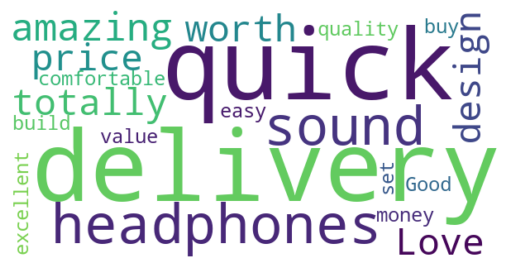

In [8]:
#Q5
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "The delivery was quick and the headphones sound amazing, totally worth the price.",
    "Battery died in two days and customer support was rude. Very disappointing.",
    "It arrived on Tuesday. The product is a black box with a cable.",
    "Love the design, very comfortable and the build quality is excellent.",
    "Terrible packaging, the box was damaged and the item stopped working.",
    "Good value for money and easy to set up, would buy again.",
]

rows = []
for r in reviews:
    s = TextBlob(r).sentiment
    if s.polarity > 0.1:
        label = "Positive"
    elif s.polarity < -0.1:
        label = "Negative"
    else:
        label = "Neutral"
    rows.append((r[:45] + "...", round(s.polarity, 2), round(s.subjectivity, 2), label))

import pandas as pd
df = pd.DataFrame(rows, columns=["review", "polarity", "subjectivity", "label"])
print(df)

# word cloud from positive reviews
pos_text = " ".join(r for r, l in zip(reviews, df["label"]) if l == "Positive")
wc = WordCloud(width=600, height=300, background_color="white").generate(pos_text)
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()

In [6]:
#Q6
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences, to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

data = ("Cricket is more than a game for many of us. Every summer the streets fill with kids        playing "
        "with a tennis ball and a wooden bat. They shout for every run and argue about every wicket. "
        "A good game teaches patience and teamwork. When the match ends the players sit together and "
        "talk about the best shot of the day. The next morning they are back on the street ready to play again.")

# 1. tokenize
tok = Tokenizer()
tok.fit_on_texts([data])
vocab = len(tok.word_index) + 1

# 2. input sequences (n-gram style)
seqs = []
for line in data.split('.'):
    ids = tok.texts_to_sequences([line])[0]
    for i in range(2, len(ids) + 1):
        seqs.append(ids[:i])

max_len = max(len(s) for s in seqs)
seqs = pad_sequences(seqs, maxlen=max_len, padding='pre')
X, y = seqs[:, :-1], to_categorical(seqs[:, -1], num_classes=vocab)

model = Sequential([
    Embedding(vocab, 32),
    LSTM(64),
    Dense(vocab, activation='softmax'),
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# 3. train
model.fit(X, y, epochs=300, verbose=0)
print("final accuracy:", round(model.evaluate(X, y, verbose=0)[1], 3))

def generate(seed, n_words=8):
    out = seed
    for _ in range(n_words):
        ids = tok.texts_to_sequences([out])[0]
        ids = pad_sequences([ids], maxlen=max_len - 1, padding='pre')
        pred = int(np.argmax(model.predict(ids, verbose=0)))
        out += " " + tok.index_word.get(pred, "")
    return out

for s in ["cricket", "every", "the"]:
    print(generate(s))

final accuracy: 1.0
cricket is more than a game for many of
every summer the streets fill with kids playing with
the next morning they are back on the street
